# 第7章：距离是建模选择

**教师参考｜全书深化稿**

## 背景与数据
Wine有不同量级的测量；高维距离集中实验采用明确的独立高斯生成点。

## 本次要回答的问题
固定折比较标准化与K值，再改变维数检验平方距离的均值与相对波动。

先写下预判，再运行，最后用实际结果解释；不需要结果符合预期才算成功。

In [1]:
from pathlib import Path
import os, sys
os.environ.setdefault("OMP_NUM_THREADS", "1")
os.environ.setdefault("OPENBLAS_NUM_THREADS", "1")
os.environ.setdefault("MKL_NUM_THREADS", "1")
root = next((p for p in [Path.cwd(), *Path.cwd().parents]
             if (p / "experiments/common.py").exists()
             and (p / "main.tex").exists()), None)
if root is None:
    raise RuntimeError("Open this notebook inside the extracted textbook project.")
sys.path.insert(0, str(root / "experiments"))
print("Project:", root)


Project: /mnt/data/book_v3


## 可检查的完整实验代码

下方与对应`experiments`脚本一致。共享的`common.py`只提供固定数据划分、保存表图和绘图设置；模型、目标、参数及比较规则在此明确写出。阅读函数后，再运行下一单元执行实验。

In [2]:
"""Chapter 7: distance metrics, scale and irrelevant dimensions."""
import numpy as np
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import cross_val_score
from scipy.spatial.distance import pdist
from common import *

def run():
    X,y,_=development('wine');splits=list(cv5().split(X,y));rows=[]
    for scaled in [False,True]:
        for k in [1,3,5,9,15,25]:
            m=KNeighborsClassifier(k)
            if scaled:m=make_pipeline(StandardScaler(),m)
            s=cross_val_score(m,X,y,cv=splits,scoring='accuracy')
            rows.append({'scaled':scaled,'neighbors':k,'accuracy_mean':s.mean(),'accuracy_std':s.std()})
    df=table('ch07_scale_k',rows);show_result(df)
    plt.figure(figsize=(6.4,4))
    for scaled in [False,True]:
        d=df[df.scaled==scaled];plt.errorbar(d.neighbors,d.accuracy_mean,yerr=d.accuracy_std,marker='o',label=f'scaled={scaled}')
    plt.xlabel('邻居数 k');plt.ylabel('五折准确率（误差棒为折间标准差）');plt.legend();figure('v3_ch07_scale')
    rng=np.random.default_rng(71);rows=[]
    for dim in [2,5,10,30,100,300]:
        P=rng.normal(size=(400,dim));d=pdist(P)
        rows.append({'dimensions':dim,'distance_mean':d.mean(),'distance_std':d.std(),'std_over_mean':d.std()/d.mean()})
    df=table('ch07_dimension',rows)
    plt.figure(figsize=(6.4,4));plt.semilogx(df.dimensions,df.std_over_mean,'o-');plt.xlabel('独立高斯特征维数');plt.ylabel('距离标准差 / 距离均值');figure('v3_ch07_concentration')
    q=np.array([0.,0.]);points=np.array([[1.,0.],[0.,2.],[2.,2.]])
    table('ch07_manual',{'point':['A','B','C'],'distance':np.linalg.norm(points-q,axis=1),'label':[0,1,1]})

In [3]:
result = run()
if result is not None:
    print(result)

 scaled  neighbors  accuracy_mean  accuracy_std
  False          1       0.675616      0.063266
  False          3       0.654680      0.048676
  False          5       0.682512      0.061138
  False          9       0.675123      0.097125
  False         15       0.674877      0.069609
  False         25       0.709606      0.099626
   True          1       0.943350      0.028945
   True          3       0.950739      0.017118
   True          5       0.950493      0.017904
   True          9       0.964778      0.022596
   True         15       0.964532      0.031948
   True         25       0.978818      0.028452


## 检查结果文件与图

下面显示该实验保存的图；所有坐标、样本与数值条件应与正文一致。数据表保存在`results/`。修改代码后，请另存结果或注明变化，不把新配置的输出与正文旧数值混用。

v3_ch07_concentration.png


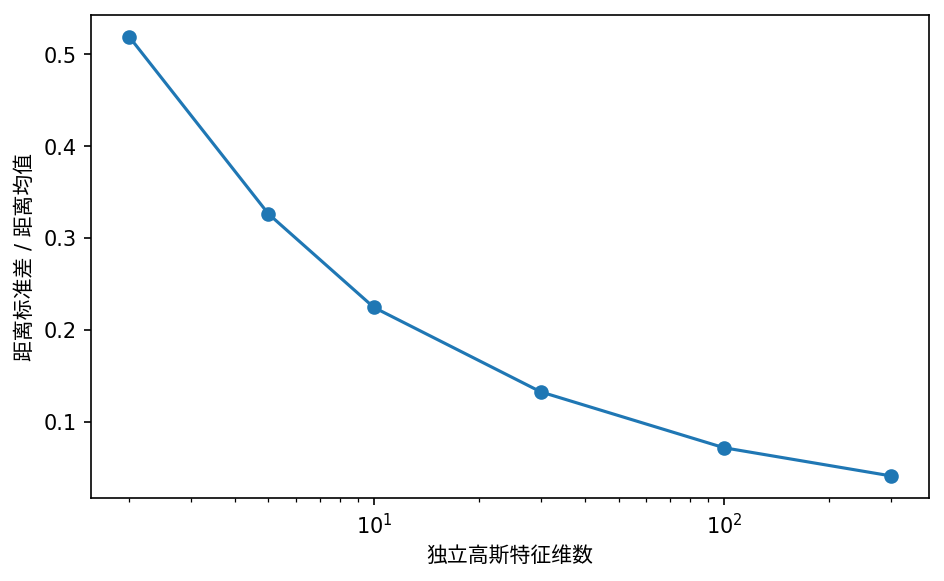

v3_ch07_scale.png


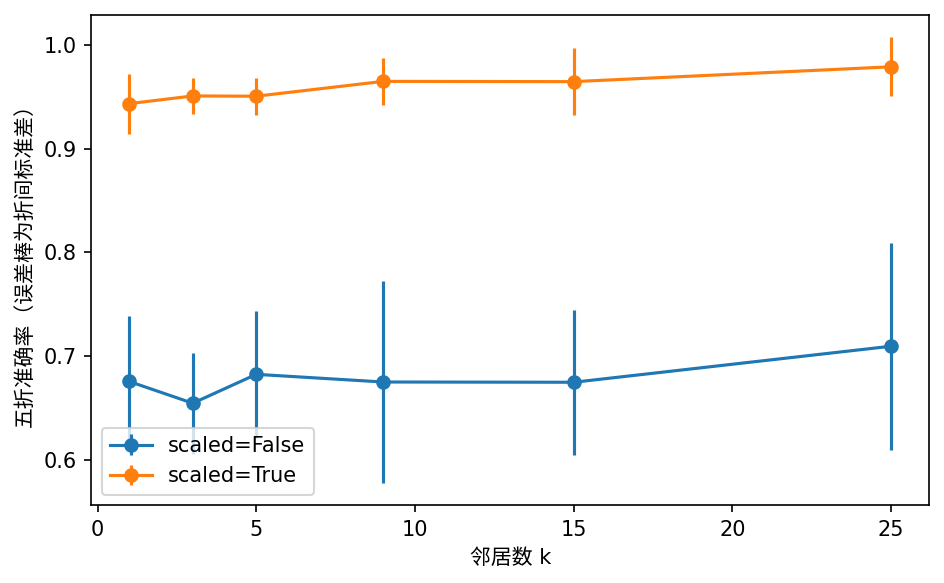

In [4]:
from IPython.display import display, Image
files = sorted((root / "figures").glob("v3_ch07_*.png"))
for path in files:
    print(path.name)
    display(Image(filename=str(path), width=720))
if not files:
    print("This experiment uses tables rather than a new figure.")

## 教师解释与核对

标准化改善本实验不证明所有特征都应等权。高维结论受生成分布假设约束；不按最终测试挑K。

完整手算解答见`teacher_manual.pdf`。如果结果与这里的参考不同，先检查数据版本、划分、软件环境、目标归一化和随机状态，不要求学生人为调成相同分数。

**评分顺序：**问题与字段角色、数据划分、算法机制、实际结果分析、证据边界。代码能运行但无法说明一项输出的含义，不算完成理解目标。